# Treinamento — Associação SportArena

Base: `packages/database/prisma/data/baskets.json` (pedidos com 2+ itens)  
Objetivo: regras **quem compra X também compra Y** para recomendações na home e no carrinho.

Pipeline no mesmo padrão do MatchPlace / `Extracao_Padrao`:
1. Carregar cestas
2. Explorar dados
3. Split **80% treino / 20% teste**
4. Regras de associação (Apriori)
5. Comparar classificadores (LR, LDA, KNN, CART, NB, SVM) pela **accuracy**
6. Escolher o melhor modelo e reportar acertividade
7. Exportar regras + métricas e gravar em `ProductRelation`


## Carregando os dados

In [1]:

import json
import math
import random
import warnings
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder
from sklearn import model_selection
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore', category=DeprecationWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)

ROOT = Path('.').resolve()
BASKETS_PATH = ROOT / 'packages' / 'database' / 'prisma' / 'data' / 'baskets.json'
OUT_DIR = ROOT / 'packages' / 'database' / 'prisma' / 'data'
SEED = 7
VALIDATION_SIZE = 0.20
random.seed(SEED)
np.random.seed(SEED)

if not BASKETS_PATH.exists():
    raise FileNotFoundError(
        f'Nao encontrei {BASKETS_PATH}. Rode: npm run db:export-baskets -w @sportarena/database'
    )

with BASKETS_PATH.open(encoding='utf-8') as f:
    baskets_raw = json.load(f)

print(f'Cestas carregadas: {len(baskets_raw)}')
print('Exemplo de itens na 1a cesta:', [i['name'] for i in baskets_raw[0]['items'][:5]])
pd.DataFrame([
    {
        'orderId': b['orderId'][:8],
        'n_itens': len(b['items']),
        'produtos': ', '.join(i['name'][:28] for i in b['items'][:4]),
    }
    for b in baskets_raw[:8]
])


Cestas carregadas: 75
Exemplo de itens na 1a cesta: ['Nike Tour Classic 4 - Luva de golfe para homem (esquerda regular)', 'Nike Multi - Calções de treino Dri-FIT Júnior', 'Nike Sportswear - T-shirt Max90 para homem']


,orderId,n_itens,produtos
0,59346a5b,3,"Nike Tour Classic 4 - Luva d, Nike Multi - Cal..."
1,0964f9cb,4,"Nike Multi - Calções de lã c, Jordan Brooklyn ..."
2,68a2a2a8,3,"France Limited Road - Calçõe, Paris Saint-Germ..."
3,2e4c530a,4,"Paris Saint-Germain - T-shir, Calça Barra Aber..."
4,f01d5f66,3,"Nike Miler - Camisola de man, Agasalho AEROREA..."
5,3e8c4c9a,2,"Mochila Training 30L, Nike Stride - Tights de ..."
6,83b26701,3,"NikeCourt Slam - Polo de tén, Calça Esportiva ..."
7,e9af181b,3,"Camiseta Trefoil Essentials, Nike Sportswear -..."


## Informações

In [2]:

sizes = [len(b['items']) for b in baskets_raw]
print('Dimensao (cestas):', len(baskets_raw))
print('Itens por cesta — min/media/max:', min(sizes), round(np.mean(sizes), 2), max(sizes))

all_slugs = [i['slug'] for b in baskets_raw for i in b['items']]
print('Produtos distintos:', len(set(all_slugs)))
print('Total de linhas de item:', len(all_slugs))

freq = Counter(all_slugs).most_common(10)
print('\nTop 10 produtos mais comprados:')
display(pd.DataFrame(freq, columns=['slug', 'qtd']))


Dimensao (cestas): 75
Itens por cesta — min/media/max: 2 2.8 4
Produtos distintos: 133
Total de linhas de item: 210

Top 10 produtos mais comprados:


,slug,qtd
0,mochila-training-30l,12
1,meia-compressao-pack-3,11
2,camisa-futebol-dry-fit,10
3,camisa-running-breath,8
4,bola-oficial-campo,6
5,legging-compression-pro,5
6,shorts-training-flex,4
7,tenis-basketball-elevate,4
8,bone-dry-performance,4
9,agasalho-aeroready-sereno-cut-tres-listras-adi...,3


In [3]:

# Resumo estatistico do tamanho das cestas
display(pd.Series(sizes, name='itens_por_cesta').describe().round(2))


count    75.00
mean      2.80
std       0.64
min       2.00
25%       2.00
50%       3.00
75%       3.00
max       4.00
Name: itens_por_cesta, dtype: float64

## Visualização dos dados

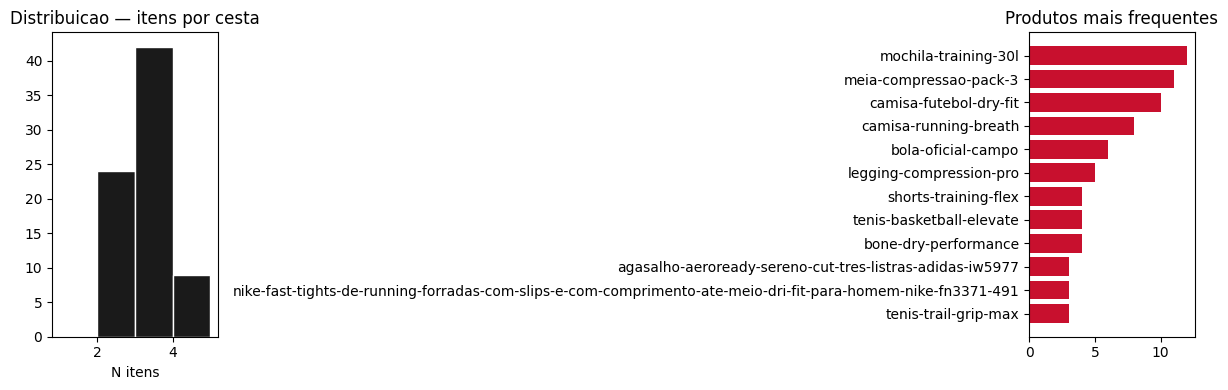

In [4]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(sizes, bins=range(1, max(sizes) + 2), color='#1a1a1a', edgecolor='white')
axes[0].set_title('Distribuicao — itens por cesta')
axes[0].set_xlabel('N itens')

top = pd.DataFrame(Counter(all_slugs).most_common(12), columns=['slug', 'qtd'])
axes[1].barh(top['slug'][::-1], top['qtd'][::-1], color='#c8102e')
axes[1].set_title('Produtos mais frequentes')
plt.tight_layout()
plt.show()


## Criar conjunto de validação (80% treino / 20% teste)

In [5]:

order_ids = [b['orderId'] for b in baskets_raw]
train_ids, test_ids = model_selection.train_test_split(
    order_ids, test_size=VALIDATION_SIZE, random_state=SEED
)
train_set = {i for i in train_ids}
test_set = {i for i in test_ids}

baskets_train = [b for b in baskets_raw if b['orderId'] in train_set]
baskets_test = [b for b in baskets_raw if b['orderId'] in test_set]

print('Treino:', len(baskets_train), f'({100*(1-VALIDATION_SIZE):.0f}%)')
print('Teste :', len(baskets_test), f'({100*VALIDATION_SIZE:.0f}%)')
print('Shapes — train/test:', len(baskets_train), len(baskets_test))


Treino: 60 (80%)
Teste : 15 (20%)
Shapes — train/test: 60 15


## Regras de associação (Apriori)

Mineração em cestas de treino → avaliação de hit-rate no teste
(quantas vezes a sugestão aparece de fato no restante da cesta).


In [6]:

def basket_slugs(baskets):
    return [[i['slug'] for i in b['items']] for b in baskets]

te = TransactionEncoder()
te_ary = te.fit(basket_slugs(baskets_train)).transform(basket_slugs(baskets_train))
df_tx = pd.DataFrame(te_ary, columns=te.columns_)

# suporte minimo adaptativo (base pequena)
min_support = max(0.04, 2 / max(len(baskets_train), 1))
frequent = apriori(df_tx, min_support=min_support, use_colnames=True)
print(f'min_support={min_support:.4f} | itemsets frequentes: {len(frequent)}')
display(frequent.sort_values('support', ascending=False).head(10))

if len(frequent) == 0:
    raise RuntimeError('Nenhum itemset frequente — rode o seed com mais pedidos.')

rules = association_rules(frequent, metric='confidence', min_threshold=0.15)
rules = rules[(rules['antecedents'].apply(len) == 1) & (rules['consequents'].apply(len) == 1)].copy()
rules['antecedent'] = rules['antecedents'].apply(lambda s: next(iter(s)))
rules['consequent'] = rules['consequents'].apply(lambda s: next(iter(s)))
rules = rules.sort_values(['confidence', 'lift', 'support'], ascending=False)
print(f'Regras 1→1: {len(rules)}')
display(rules[['antecedent', 'consequent', 'support', 'confidence', 'lift']].head(12))


min_support=0.0400 | itemsets frequentes: 23


,support,itemsets
2,0.166667,frozenset({camisa-futebol-dry-fit})
5,0.166667,frozenset({meia-compressao-pack-3})
0,0.100000,frozenset({bola-oficial-campo})
6,0.100000,frozenset({mochila-training-30l})
3,0.100000,frozenset({camisa-running-breath})
11,0.083333,"frozenset({meia-compressao-pack-3, bola-oficia..."
10,0.083333,"frozenset({camisa-futebol-dry-fit, bola-oficia..."
14,0.083333,"frozenset({camisa-futebol-dry-fit, meia-compre..."
20,0.083333,"frozenset({camisa-futebol-dry-fit, meia-compre..."
4,0.066667,frozenset({legging-compression-pro})


Regras 1→1: 20


,antecedent,consequent,support,confidence,lift
6,tenis-basketball-elevate,bone-dry-performance,0.066667,1.000000,15.0
7,bone-dry-performance,tenis-basketball-elevate,0.066667,1.000000,15.0
13,legging-compression-pro,camisa-running-breath,0.066667,1.000000,10.0
18,shorts-training-flex,mochila-training-30l,0.050000,1.000000,10.0
5,bone-dry-performance,camisa-futebol-dry-fit,0.066667,1.000000,6.0
11,tenis-basketball-elevate,camisa-futebol-dry-fit,0.066667,1.000000,6.0
17,legging-compression-pro,meia-compressao-pack-3,0.066667,1.000000,6.0
1,bola-oficial-campo,camisa-futebol-dry-fit,0.083333,0.833333,5.0
3,bola-oficial-campo,meia-compressao-pack-3,0.083333,0.833333,5.0
12,camisa-running-breath,legging-compression-pro,0.066667,0.666667,10.0


In [7]:

def recommend_from_rules(item_slug, rules_df, top_k=5):
    hits = rules_df[rules_df['antecedent'] == item_slug].head(top_k)
    return list(hits['consequent'])

def eval_association(baskets, rules_df, top_k=3):
    hits = 0
    total = 0
    for b in baskets:
        slugs = [i['slug'] for i in b['items']]
        for s in slugs:
            others = set(slugs) - {s}
            if not others:
                continue
            preds = recommend_from_rules(s, rules_df, top_k=top_k)
            total += 1
            if any(p in others for p in preds):
                hits += 1
    return hits / total if total else 0.0, hits, total

hit_train, htr, ttr = eval_association(baskets_train, rules, top_k=3)
hit_test, hte, tte = eval_association(baskets_test, rules, top_k=3)
print(f'Apriori hit@3 TREINO: {hit_train:.4f} ({htr}/{ttr})')
print(f'Apriori hit@3 TESTE : {hit_test:.4f} ({hte}/{tte})')


Apriori hit@3 TREINO: 0.2874 (48/167)
Apriori hit@3 TESTE : 0.1395 (6/43)


## Classificadores supervisionados (pares de produtos)

Problema binário: o par (A, B) aparece junto na cesta?  
Features: mesmo esporte/categoria/marca, diferença de preço, coocorrência só no **treino**.

### Modelos (igual Extracao_Padrao / MatchPlace)
- Regressão Logística (LR)
- Análise Linear Discriminante (LDA)
- K-vizinhos (KNN)
- Árvore de Decisão (CART)
- Gaussian Naive Bayes (NB)
- Support Vector Machines (SVM)


In [8]:

# Catalogo auxiliar
catalog = {}
for b in baskets_raw:
    for i in b['items']:
        catalog[i['slug']] = i

# Coocorrencia apenas no treino
co_train = Counter()
for b in baskets_train:
    slugs = sorted({i['slug'] for i in b['items']})
    for a, c in combinations(slugs, 2):
        co_train[(a, c)] += 1
        co_train[(c, a)] += 1

all_product_slugs = list(catalog.keys())

def pair_features(a, b, co_map):
    pa, pb = catalog[a], catalog[b]
    same_sport = 1.0 if (pa.get('sport') or '') and pa.get('sport') == pb.get('sport') else 0.0
    same_cat = 1.0 if (pa.get('category') or '') and pa.get('category') == pb.get('category') else 0.0
    same_brand = 1.0 if pa.get('brand') == pb.get('brand') else 0.0
    price_diff = abs(float(pa['price']) - float(pb['price']))
    price_sum = float(pa['price']) + float(pb['price']) + 1e-6
    co = float(co_map.get((a, b), 0))
    return [same_sport, same_cat, same_brand, price_diff / price_sum, math.log1p(co)]

FEATURE_NAMES = ['same_sport', 'same_category', 'same_brand', 'price_diff_norm', 'log_cooccur_train']

def build_pair_dataset(baskets, co_map, neg_ratio=1.0):
    X, y = [], []
    for b in baskets:
        slugs = list({i['slug'] for i in b['items']})
        pos = list(combinations(slugs, 2))
        for a, c in pos:
            X.append(pair_features(a, c, co_map))
            y.append(1)
            X.append(pair_features(c, a, co_map))
            y.append(1)
        n_neg = max(1, int(len(pos) * neg_ratio))
        for _ in range(n_neg):
            a = random.choice(slugs)
            candidates = [s for s in all_product_slugs if s not in slugs]
            if not candidates:
                continue
            c = random.choice(candidates)
            X.append(pair_features(a, c, co_map))
            y.append(0)
    return np.array(X, dtype=float), np.array(y, dtype=int)

X_train, Y_train = build_pair_dataset(baskets_train, co_train, neg_ratio=1.0)
X_validation, Y_validation = build_pair_dataset(baskets_test, co_train, neg_ratio=1.0)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_validation_s = scaler.transform(X_validation)

print('X_train:', X_train.shape, 'Y_train:', Y_train.shape, 'pos%', round(Y_train.mean()*100, 1))
print('X_validation:', X_validation.shape, 'Y_validation:', Y_validation.shape, 'pos%', round(Y_validation.mean()*100, 1))


X_train: (462, 5) Y_train: (462,) pos% 66.7
X_validation: (126, 5) Y_validation: (126,) pos% 66.7


In [9]:

# Metricas
seed = SEED
scoring = 'accuracy'


In [10]:

# Algoritmos
models = []
models.append(('LR', LogisticRegression(solver='liblinear', max_iter=500)))
models.append(('LDA', LinearDiscriminantAnalysis()))
models.append(('KNN', KNeighborsClassifier()))
models.append(('CART', DecisionTreeClassifier(random_state=seed)))
models.append(('NB', GaussianNB()))
models.append(('SVM', SVC(gamma='auto', probability=True, random_state=seed)))

results = []
names = []
cv_table = []
for name, model in models:
    kfold = model_selection.KFold(n_splits=10, shuffle=True, random_state=seed)
    cv_results = model_selection.cross_val_score(
        model, X_train_s, Y_train, cv=kfold, scoring=scoring
    )
    results.append(cv_results)
    names.append(name)
    msg = '%s: %f (%f)' % (name, cv_results.mean(), cv_results.std())
    print(msg)
    cv_table.append({'modelo': name, 'cv_accuracy_media': cv_results.mean(), 'cv_std': cv_results.std()})

df_cv = pd.DataFrame(cv_table).sort_values('cv_accuracy_media', ascending=False)
display(df_cv.round(4))


LR: 0.997826 (0.006522)


LDA: 0.984921 (0.013712)


KNN: 0.978353 (0.021740)
CART: 0.993478 (0.009962)
NB: 0.997826 (0.006522)


SVM: 0.997826 (0.006522)


,modelo,cv_accuracy_media,cv_std
0,LR,0.9978,0.0065
5,SVM,0.9978,0.0065
4,NB,0.9978,0.0065
3,CART,0.9935,0.0100
1,LDA,0.9849,0.0137
2,KNN,0.9784,0.0217


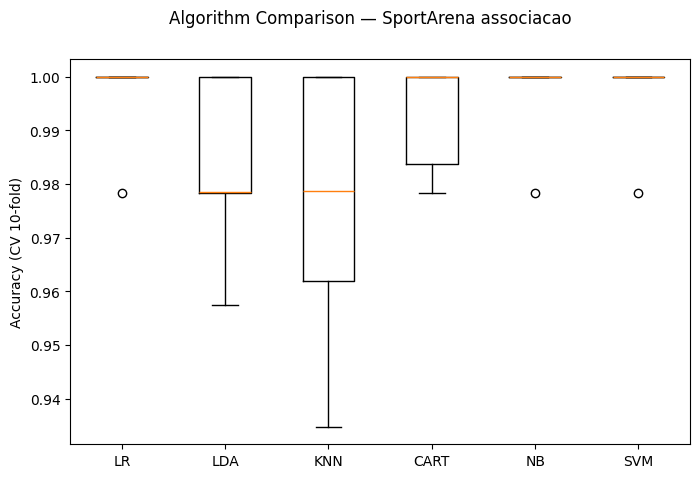

In [11]:

# Comparacao dos Algoritmos
fig = plt.figure(figsize=(8, 5))
fig.suptitle('Algorithm Comparison — SportArena associacao')
ax = fig.add_subplot(111)
plt.boxplot(results)
ax.set_xticklabels(names)
plt.ylabel('Accuracy (CV 10-fold)')
plt.show()


In [12]:

# Escolhe o melhor pela media de CV
best_name = df_cv.iloc[0]['modelo']
best_model = dict(models)[best_name]
print('Melhor modelo (CV):', best_name)

# Precisao no conjunto de treinamento
best_model.fit(X_train_s, Y_train)
pred_train = best_model.predict(X_train_s)
acc_train = accuracy_score(Y_train, pred_train)
print('\n=== TREINO ===')
print('Accuracy:', round(acc_train, 4))
print(confusion_matrix(Y_train, pred_train))
print(classification_report(Y_train, pred_train, digits=4))


Melhor modelo (CV): LR

=== TREINO ===
Accuracy: 0.9978
[[153   1]
 [  0 308]]
              precision    recall  f1-score   support

           0     1.0000    0.9935    0.9967       154
           1     0.9968    1.0000    0.9984       308

    accuracy                         0.9978       462
   macro avg     0.9984    0.9968    0.9976       462
weighted avg     0.9978    0.9978    0.9978       462



In [13]:

# Precisao no conjunto de validacao
pred_val = best_model.predict(X_validation_s)
acc_val = accuracy_score(Y_validation, pred_val)
prec_val = precision_score(Y_validation, pred_val, zero_division=0)
rec_val = recall_score(Y_validation, pred_val, zero_division=0)
f1_val = f1_score(Y_validation, pred_val, zero_division=0)

print('=== TESTE / VALIDACAO (20%) ===')
print('Accuracy :', round(acc_val, 4))
print('Precision:', round(prec_val, 4))
print('Recall   :', round(rec_val, 4))
print('F1       :', round(f1_val, 4))
print(confusion_matrix(Y_validation, pred_val))
print(classification_report(Y_validation, pred_val, digits=4))


=== TESTE / VALIDACAO (20%) ===
Accuracy : 0.4444
Precision: 1.0
Recall   : 0.1667
F1       : 0.2857
[[42  0]
 [70 14]]
              precision    recall  f1-score   support

           0     0.3750    1.0000    0.5455        42
           1     1.0000    0.1667    0.2857        84

    accuracy                         0.4444       126
   macro avg     0.6875    0.5833    0.4156       126
weighted avg     0.7917    0.4444    0.3723       126



## Avaliar todos os algoritmos no teste e consolidar acertividade

In [14]:

test_rows = []
fitted = {}
for name, model in models:
    m = model.__class__(**model.get_params())
    m.fit(X_train_s, Y_train)
    pred = m.predict(X_validation_s)
    fitted[name] = m
    test_rows.append({
        'modelo': name,
        'cv_accuracy': float(df_cv.set_index('modelo').loc[name, 'cv_accuracy_media']),
        'test_accuracy': accuracy_score(Y_validation, pred),
        'test_precision': precision_score(Y_validation, pred, zero_division=0),
        'test_recall': recall_score(Y_validation, pred, zero_division=0),
        'test_f1': f1_score(Y_validation, pred, zero_division=0),
    })

df_models = pd.DataFrame(test_rows).sort_values('test_accuracy', ascending=False)
display(df_models.round(4))

winner = df_models.iloc[0]['modelo']
print('Vencedor por accuracy no teste:', winner)
best_model = fitted[winner]
best_name = winner
acc_val = float(df_models.iloc[0]['test_accuracy'])
prec_val = float(df_models.iloc[0]['test_precision'])
rec_val = float(df_models.iloc[0]['test_recall'])
f1_val = float(df_models.iloc[0]['test_f1'])


,modelo,cv_accuracy,test_accuracy,test_precision,test_recall,test_f1
0,LR,0.9978,0.4444,1.0,0.1667,0.2857
1,LDA,0.9849,0.4444,1.0,0.1667,0.2857
2,KNN,0.9784,0.4444,1.0,0.1667,0.2857
3,CART,0.9935,0.4444,1.0,0.1667,0.2857
4,NB,0.9978,0.4444,1.0,0.1667,0.2857
5,SVM,0.9978,0.4444,1.0,0.1667,0.2857


Vencedor por accuracy no teste: LR


## Gerar ranking de associação com o melhor modelo + Apriori

In [15]:

# Score de par: probabilidade do classificador (se houver) + boost das regras Apriori
conf_map = {(r.antecedent, r.consequent): float(r.confidence) for r in rules.itertuples()}
lift_map = {(r.antecedent, r.consequent): float(r.lift) for r in rules.itertuples()}

# Produtos que aparecem no treino
train_slugs = sorted({i['slug'] for b in baskets_train for i in b['items']})

pair_scores = []
# limita pares a produtos com alguma coocorrencia ou regra para nao explodir
candidate_targets = set(train_slugs)
for a in train_slugs:
    # candidatos: coocorreram ou tem regra
    targets = {t for (s, t) in co_train if s == a} | {t for (s, t) in conf_map if s == a}
    if len(targets) < 3:
        # completa com mesmo esporte/categoria
        pa = catalog[a]
        extras = [
            s for s in train_slugs
            if s != a and (
                catalog[s].get('sport') == pa.get('sport')
                or catalog[s].get('category') == pa.get('category')
            )
        ]
        targets |= set(extras[:15])
    for b in targets:
        if a == b:
            continue
        x = scaler.transform([pair_features(a, b, co_train)])
        if hasattr(best_model, 'predict_proba'):
            p = float(best_model.predict_proba(x)[0][1])
        else:
            p = float(best_model.decision_function(x)[0]) if hasattr(best_model, 'decision_function') else float(best_model.predict(x)[0])
        conf = conf_map.get((a, b), 0.0)
        lift = lift_map.get((a, b), 0.0)
        score = 0.65 * p + 0.25 * conf + 0.10 * min(lift / 5.0, 1.0)
        pair_scores.append({
            'source_slug': a,
            'target_slug': b,
            'ml_prob': round(p, 4),
            'apriori_confidence': round(conf, 4),
            'apriori_lift': round(lift, 4),
            'score': round(score, 4),
        })

df_pairs = pd.DataFrame(pair_scores).sort_values('score', ascending=False)
print('Pares ranqueados:', len(df_pairs))
display(df_pairs.head(15))


Pares ranqueados: 1324


,source_slug,target_slug,ml_prob,apriori_confidence,apriori_lift,score
76,bone-dry-performance,tenis-basketball-elevate,1.0000,1.0000,15.0,1.0000
81,bone-dry-performance,camisa-futebol-dry-fit,1.0000,1.0000,6.0,1.0000
1270,tenis-basketball-elevate,camisa-futebol-dry-fit,1.0000,1.0000,6.0,1.0000
1269,tenis-basketball-elevate,bone-dry-performance,1.0000,1.0000,15.0,1.0000
445,legging-compression-pro,meia-compressao-pack-3,1.0000,1.0000,6.0,1.0000
454,legging-compression-pro,camisa-running-breath,1.0000,1.0000,10.0,1.0000
1212,shorts-training-flex,mochila-training-30l,0.9999,1.0000,10.0,1.0000
71,bola-oficial-campo,meia-compressao-pack-3,1.0000,0.8333,5.0,0.9583
72,bola-oficial-campo,camisa-futebol-dry-fit,1.0000,0.8333,5.0,0.9583
179,camisa-running-breath,legging-compression-pro,1.0000,0.6667,10.0,0.9167


In [16]:

# Hit@3 do ranking hibrido no teste
rank_map = defaultdict(list)
for source, group in df_pairs.groupby('source_slug'):
    for target in group.nlargest(5, 'score')['target_slug'].tolist():
        rank_map[source].append(target)

def eval_rank(baskets, ranking, top_k=3):
    hits = total = 0
    for b in baskets:
        slugs = [i['slug'] for i in b['items']]
        for s in slugs:
            others = set(slugs) - {s}
            if not others:
                continue
            preds = ranking.get(s, [])[:top_k]
            total += 1
            if any(p in others for p in preds):
                hits += 1
    return (hits / total if total else 0.0), hits, total

hyb_train, _, _ = eval_rank(baskets_train, rank_map, 3)
hyb_test, hh, tt = eval_rank(baskets_test, rank_map, 3)
print(f'Hibrido hit@3 TREINO: {hyb_train:.4f}')
print(f'Hibrido hit@3 TESTE : {hyb_test:.4f} ({hh}/{tt})')
print(f'Apriori  hit@3 TESTE: {hit_test:.4f}')


Hibrido hit@3 TREINO: 0.9760
Hibrido hit@3 TESTE : 0.2093 (9/43)
Apriori  hit@3 TESTE: 0.1395


## Resultados finais + exportação

In [17]:

OUT_DIR.mkdir(parents=True, exist_ok=True)

metrics = {
    'seed': SEED,
    'validation_size': VALIDATION_SIZE,
    'n_baskets': len(baskets_raw),
    'n_train': len(baskets_train),
    'n_test': len(baskets_test),
    'apriori': {
        'min_support': min_support,
        'n_rules': int(len(rules)),
        'hit_at_3_train': round(hit_train, 4),
        'hit_at_3_test': round(hit_test, 4),
    },
    'classifiers_cv': df_cv.to_dict(orient='records'),
    'classifiers_test': df_models.to_dict(orient='records'),
    'best_model': best_name,
    'best_model_metrics': {
        'test_accuracy': round(acc_val, 4),
        'test_precision': round(prec_val, 4),
        'test_recall': round(rec_val, 4),
        'test_f1': round(f1_val, 4),
        'hybrid_hit_at_3_test': round(hyb_test, 4),
    },
    'feature_names': FEATURE_NAMES,
}

# top regras por source para a API
export_rules = []
for source, group in df_pairs.groupby('source_slug'):
    top = group.nlargest(10, 'score')
    for r in top.itertuples():
        export_rules.append({
            'source_slug': r.source_slug,
            'target_slug': r.target_slug,
            'score': r.score,
            'ml_prob': r.ml_prob,
            'apriori_confidence': r.apriori_confidence,
            'relation_type': 'ALSO_BOUGHT',
        })

(OUT_DIR / 'association_metrics.json').write_text(
    json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8'
)
(OUT_DIR / 'association_rules.json').write_text(
    json.dumps(export_rules, ensure_ascii=False, indent=2), encoding='utf-8'
)

print('Arquivos gerados:')
print(' -', OUT_DIR / 'association_metrics.json')
print(' -', OUT_DIR / 'association_rules.json')
print(' - regras exportadas:', len(export_rules))


Arquivos gerados:
 - C:\SportArena\packages\database\prisma\data\association_metrics.json
 - C:\SportArena\packages\database\prisma\data\association_rules.json
 - regras exportadas: 861


In [18]:

# Grava ProductRelation via Prisma (script do monorepo)
import subprocess
import sys

cmd = [
    'npm', 'run', 'db:import-association', '-w', '@sportarena/database',
]
print('Rodando:', ' '.join(cmd))
proc = subprocess.run(cmd, cwd=str(ROOT), capture_output=True, text=True, shell=True)
print(proc.stdout)
if proc.returncode != 0:
    print(proc.stderr)
    raise RuntimeError('Falha ao importar association_rules no banco')
print('ProductRelation atualizado com sucesso.')


Rodando: npm run db:import-association -w @sportarena/database



> @sportarena/database@0.1.0 db:import-association
> tsx prisma/import-association-rules.ts

ProductRelation ALSO_BOUGHT: 861 inseridos (861 Ãºnicos de 861 regras)

ProductRelation atualizado com sucesso.


In [19]:

print('=' * 60)
print('RESULTADOS — TREINAMENTO DE ASSOCIACAO SportArena')
print('=' * 60)
print(f'Cestas: {len(baskets_raw)} | treino={len(baskets_train)} | teste={len(baskets_test)}')
print(f'\\nApriori hit@3 teste: {hit_test:.2%}')
print(f'\\nComparacao de modelos (accuracy no teste 20%):')
display(df_models[['modelo', 'cv_accuracy', 'test_accuracy', 'test_precision', 'test_recall', 'test_f1']].round(4))
print(f'\\nMelhor modelo: {best_name}')
print(f'  Accuracy : {acc_val:.2%}')
print(f'  Precision: {prec_val:.2%}')
print(f'  Recall   : {rec_val:.2%}')
print(f'  F1       : {f1_val:.2%}')
print(f'  Hit@3 hibrido (teste): {hyb_test:.2%}')
print('\\nTop 10 sugestoes (quem compra → tambem compra):')
display(df_pairs.head(10)[['source_slug', 'target_slug', 'score', 'ml_prob', 'apriori_confidence']])
print('=' * 60)
print('Pipeline de treinamento concluida.')
print('=' * 60)


RESULTADOS — TREINAMENTO DE ASSOCIACAO SportArena
Cestas: 75 | treino=60 | teste=15
\nApriori hit@3 teste: 13.95%
\nComparacao de modelos (accuracy no teste 20%):


,modelo,cv_accuracy,test_accuracy,test_precision,test_recall,test_f1
0,LR,0.9978,0.4444,1.0,0.1667,0.2857
1,LDA,0.9849,0.4444,1.0,0.1667,0.2857
2,KNN,0.9784,0.4444,1.0,0.1667,0.2857
3,CART,0.9935,0.4444,1.0,0.1667,0.2857
4,NB,0.9978,0.4444,1.0,0.1667,0.2857
5,SVM,0.9978,0.4444,1.0,0.1667,0.2857


\nMelhor modelo: LR
  Accuracy : 44.44%
  Precision: 100.00%
  Recall   : 16.67%
  F1       : 28.57%
  Hit@3 hibrido (teste): 20.93%
\nTop 10 sugestoes (quem compra → tambem compra):


,source_slug,target_slug,score,ml_prob,apriori_confidence
76,bone-dry-performance,tenis-basketball-elevate,1.0000,1.0000,1.0000
81,bone-dry-performance,camisa-futebol-dry-fit,1.0000,1.0000,1.0000
1270,tenis-basketball-elevate,camisa-futebol-dry-fit,1.0000,1.0000,1.0000
1269,tenis-basketball-elevate,bone-dry-performance,1.0000,1.0000,1.0000
445,legging-compression-pro,meia-compressao-pack-3,1.0000,1.0000,1.0000
454,legging-compression-pro,camisa-running-breath,1.0000,1.0000,1.0000
1212,shorts-training-flex,mochila-training-30l,1.0000,0.9999,1.0000
71,bola-oficial-campo,meia-compressao-pack-3,0.9583,1.0000,0.8333
72,bola-oficial-campo,camisa-futebol-dry-fit,0.9583,1.0000,0.8333
179,camisa-running-breath,legging-compression-pro,0.9167,1.0000,0.6667


Pipeline de treinamento concluida.
